In [55]:
import h5py
import numpy as np
from matplotlib import pyplot as plt
import cv2
import sys
sys.path.append(r'C:/Users/w37262do/Documents/git/IR_preprocessing')
from src.preprocessing_tk import *

In [76]:
# Import Data - NOCL
h5_nocl = h5py.File(
    r"D:/datasets/qcl2026_raw/annotated_spectra_dataset.h5"
)

protocol_name = 'greedy'
protocol_args = ['none','none','none','2nd','none',]
preprocessing_tk = get_processing_tk_from_name(protocol_name,protocol_args)

spectra_nocl = h5_nocl['spectra'][:]
spectra_nocl,wavenumbers = preprocessing_tk.spectral_transform(spectra_nocl,wavenumbers=np.load(r"D:/datasets/qcl2026_raw/wavenumbers.npy"))
label_nocl = h5_nocl['tissue_class'][:]

In [77]:
v = spectra_nocl[:,0]
v = np.clip(v, np.percentile(v,1),np.percentile(v,99))

hist, bin_edges = np.histogram(v,bins=256)
bin_centres = (bin_edges[1:]+bin_edges[:-1])/2

cdf = hist.cumsum()

## cdfv = cdf[np.abs(v[:,np.newaxis] - bin_centres[np.newaxis,:]).argmin(-1)] ## OLD! does it by indexing into discretised cdf
cdfv = np.interp(v, bin_centres, cdf) ## NEW! does it by interpolating the cdf -- this is faster too

eqv = ((cdfv - cdf.min()) / (len(cdfv) - cdf.min()))

## new

In [78]:
low_percentile_clip = 1
high_percentile_clip = 99

v = spectra_nocl

low_percentile = np.percentile(v,low_percentile_clip,axis=0)
high_percentile = np.percentile(v,high_percentile_clip,axis=0)

v = np.clip(v, low_percentile,high_percentile)

In [79]:
nbins = 256
hists = []
bin_edges = []
bin_centres = []
cdfs = []
eqvs = []
for wvidx in range(v.shape[-1]):
    hist, bin_edge = np.histogram(v[:,wvidx],bins=nbins)
    bin_centre = (bin_edge[1:]+bin_edge[:-1])/2
    hists.append(hist)
    bin_edges.append(bin_edge)
    bin_centres.append(bin_centre)

    cdf = hist.cumsum()
    cdfs.append(cdf)

    cdfv = np.interp(v[:,wvidx], bin_centre, cdf)
    eqv = ((cdfv - cdf.min()) / (len(cdfv) - cdf.min()))
    eqvs.append(eqv)

hists = np.array(hists)
bin_edges = np.array(bin_edges)
bin_centres = np.array(bin_centres)
cdfs = np.array(cdfs)
eqvs = np.array(eqvs).T

In [80]:
def hist_eq(spectra):
    spectra = np.clip(spectra, low_percentile,high_percentile)
    eqvs = []
    for wvidx in range(spectra.shape[-1]):
        cdfv = np.interp(spectra[:,wvidx], bin_centres[wvidx], cdfs[wvidx])
        eqv = ((cdfv - cdf.min()) / (len(cdfv) - cdf.min()))
        eqvs.append(eqv)
    eqvs = np.array(eqvs).T
    return eqvs

In [145]:
f = h5py.File(r"D:\datasets\qcl2026_raw\spectral\s03_c022.h5")
spectra = f['spectra'][:]
f.close()

mask = cv2.imread(r"D:\datasets\qcl2026_raw\mask\s03_c022.png")[...,0] / 255.0

In [146]:
h, w, c = spectra.shape
transformed_spectra,_ = preprocessing_tk.spectral_transform(spectra[mask == 1],wavenumbers=np.load(r"D:/datasets/qcl2026_raw/wavenumbers.npy"))

# comparison deriv img
og_image = np.zeros((h, w, transformed_spectra.shape[-1]))
og_image[np.where(mask == 1)] = transformed_spectra

transformed_spectra = hist_eq(transformed_spectra)
transformed_image = np.zeros((h, w, transformed_spectra.shape[-1]))
transformed_image[np.where(mask == 1)] = transformed_spectra

IndexError: index 1500 is out of bounds for axis 2 with size 405

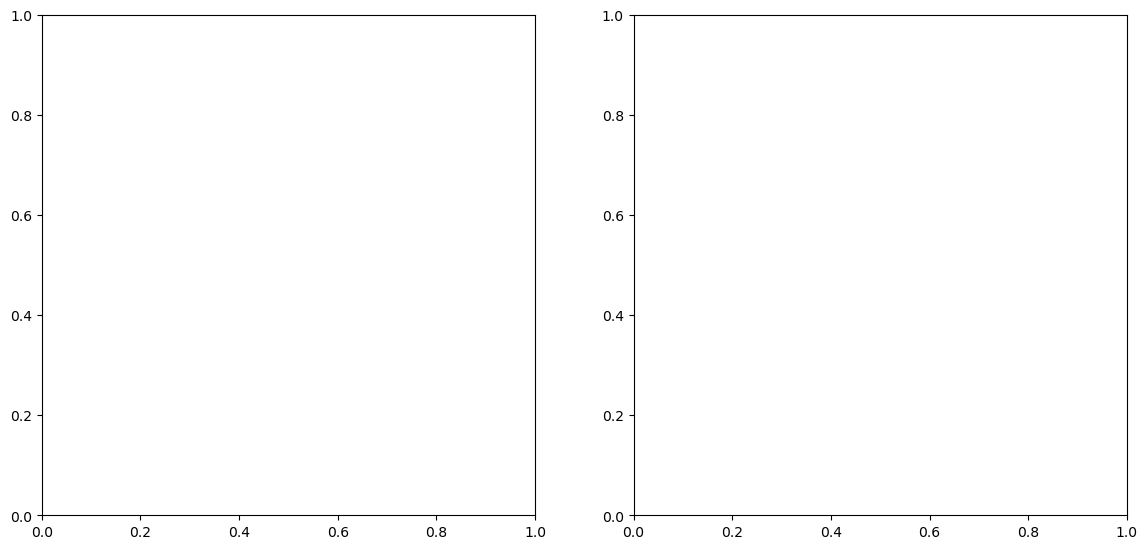

In [149]:
fig,ax = plt.subplots(1,2,figsize=(14,6.5))
wvshow = np.abs(wavenumbers - 1500)
ax[0].matshow(og_image[...,wvshow],cmap='bone'); ax[0].set_title(f"Raw Image/Spectra @ {wvshow}")
ax[1].matshow(transformed_image[...,wvshow],cmap='bone'); ax[1].set_title(f"Histogram Equalised @ {wvshow}")